<a href="https://colab.research.google.com/github/UditKumar0001/Deep-Learning/blob/main/CNN_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import Dense, Dropout, Conv2D, Flatten, MaxPooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

In [46]:
df = pd.read_csv('/mnist_train.csv')
df_test = pd.read_csv('/mnist_test (1).csv')

In [47]:
df.head()

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [48]:
df.shape

(60000, 785)

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Columns: 785 entries, label to 28x28
dtypes: int64(785)
memory usage: 359.3 MB


In [50]:
df.columns

Index(['label', '1x1', '1x2', '1x3', '1x4', '1x5', '1x6', '1x7', '1x8', '1x9',
       ...
       '28x19', '28x20', '28x21', '28x22', '28x23', '28x24', '28x25', '28x26',
       '28x27', '28x28'],
      dtype='object', length=785)

In [51]:
df.isnull().sum()

,0
label,0
1x1,0
1x2,0
1x3,0
1x4,0
...,...
28x24,0
28x25,0
28x26,0
28x27,0


In [52]:
X_train = df.drop('label', axis=1).values
X_test = df_test.drop('label', axis=1).values
y_train = df['label'].values
y_test = df_test['label'].values

In [53]:
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

In [54]:
X_train_img = X_train.reshape(-1, 28, 28)
X_test_img = X_test.reshape(-1, 28, 28)

In [55]:
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

In [56]:
perceptron = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(10, activation='softmax')
])

In [57]:
perceptron.compile(optimizer='sgd', loss='categorical_crossentropy', metrics=['accuracy'])

In [58]:
history_perceptron = perceptron.fit(X_train_img, y_train_cat, epochs=5, batch_size= 32, validation_data=(X_test_img, y_test_cat), verbose=1)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8115 - loss: 0.7816 - val_accuracy: 0.8823 - val_loss: 0.4798
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8805 - loss: 0.4566 - val_accuracy: 0.8959 - val_loss: 0.4004
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8916 - loss: 0.4036 - val_accuracy: 0.9022 - val_loss: 0.3677
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8973 - loss: 0.3771 - val_accuracy: 0.9063 - val_loss: 0.3488
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9003 - loss: 0.3603 - val_accuracy: 0.9087 - val_loss: 0.3368


In [59]:
acc_percep = perceptron.evaluate(X_test_img, y_test_cat, verbose=0)[1]
acc_percep

0.9086999893188477

In [60]:
ann = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(10, activation='softmax')
])

In [61]:
ann.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [62]:
history_ann = ann.fit(X_train_img, y_train_cat, epochs=5, batch_size= 32, validation_data=(X_test_img, y_test_cat), verbose=1)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9253 - loss: 0.2511 - val_accuracy: 0.9543 - val_loss: 0.1470
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9657 - loss: 0.1111 - val_accuracy: 0.9643 - val_loss: 0.1144
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9762 - loss: 0.0777 - val_accuracy: 0.9736 - val_loss: 0.0883
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9809 - loss: 0.0616 - val_accuracy: 0.9729 - val_loss: 0.0902
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9842 - loss: 0.0495 - val_accuracy: 0.9737 - val_loss: 0.0942


In [63]:
acc_ann = ann.evaluate(X_test_img, y_test_cat, verbose=0)[1]
acc_ann

0.9736999869346619

In [64]:
X_train_cnn = X_train.reshape(-1, 28, 28,1)
X_test_cnn = X_test.reshape(-1, 28, 28,1)

In [65]:
cnn = Sequential([
    Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    Conv2D(64, kernel_size=(3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

In [66]:
cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [67]:
history_cnn = cnn.fit(X_train_cnn, y_train_cat, epochs=5, batch_size= 32, validation_data=(X_test_cnn, y_test_cat), verbose=1)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 56s 29ms/step - accuracy: 0.9370 - loss: 0.2081 - val_accuracy: 0.9828 - val_loss: 0.0526
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 55s 29ms/step - accuracy: 0.9768 - loss: 0.0792 - val_accuracy: 0.9875 - val_loss: 0.0360
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 29ms/step - accuracy: 0.9824 - loss: 0.0586 - val_accuracy: 0.9907 - val_loss: 0.0280
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 56s 30ms/step - accuracy: 0.9850 - loss: 0.0492 - val_accuracy: 0.9920 - val_loss: 0.0242
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 56s 30ms/step - accuracy: 0.9881 - loss: 0.0407 - val_accuracy: 0.9912 - val_loss: 0.0264


In [68]:
acc_cnn = cnn.evaluate(X_test_cnn, y_test_cat, verbose=0)[1]
acc_cnn

0.9911999702453613

In [71]:
def plot_training(history, title):
  plt.figure(figsize=(12, 4))
  plt.subplot(1, 2, 1)
  plt.plot(history.history['accuracy'], label='Train')
  plt.plot(history.history['val_accuracy'], label='Val')
  plt.title(f'{title} Accuracy')
  plt.xlabel('Epochs')
  plt.ylabel('Accuracy')
  plt.legend()

  plt.subplot(1, 2, 2)
  plt.plot(history.history['loss'], label='Train')
  plt.plot(history.history['val_loss'], label='Val')
  plt.title(f'{title} Loss')
  plt.xlabel('Epochs')
  plt.ylabel('Loss')
  plt.legend()

  plt.tight_layout()
  plt.show()

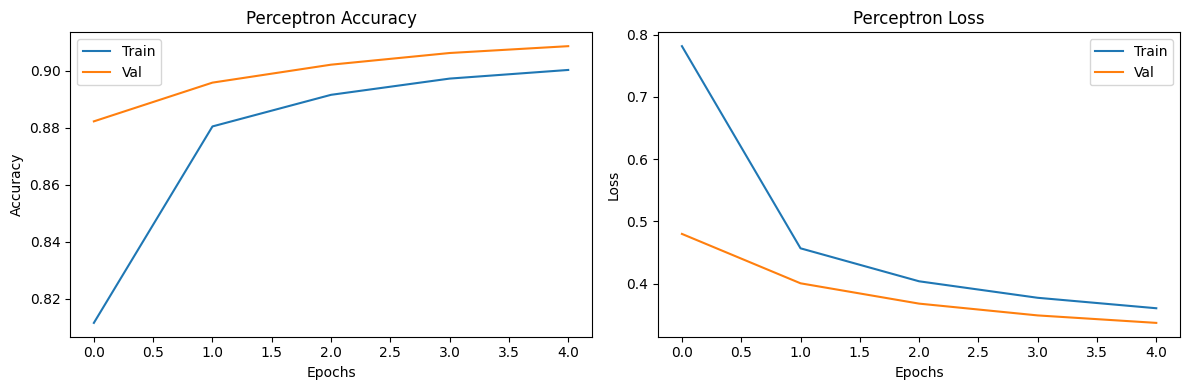

In [72]:
plot_training(history_perceptron, 'Perceptron')

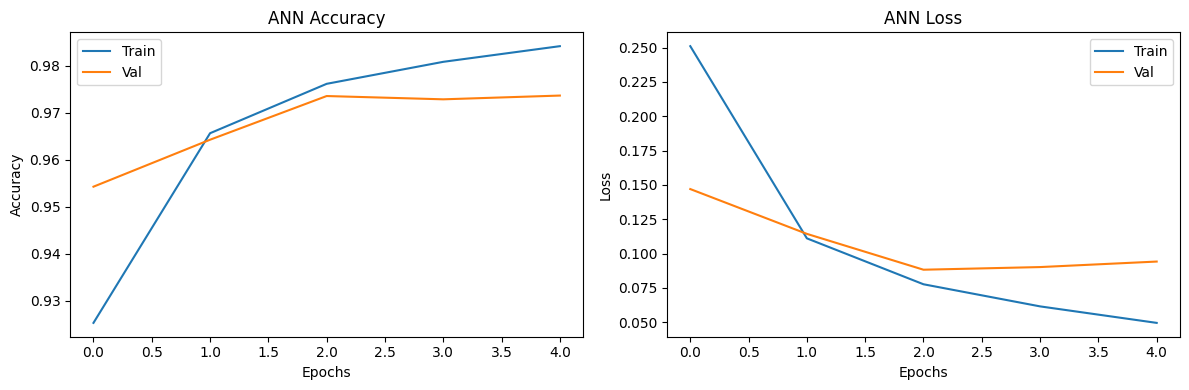

In [73]:
plot_training(history_ann, 'ANN')

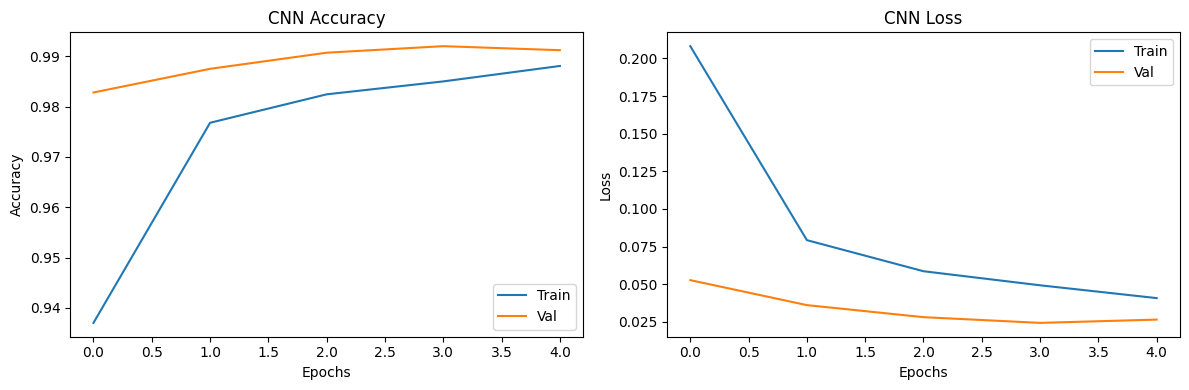

In [74]:
plot_training(history_cnn, 'CNN')

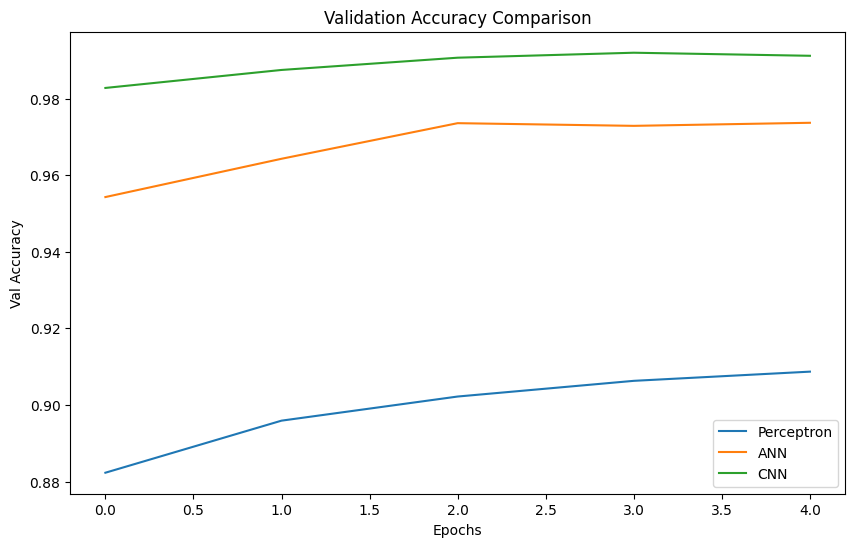

In [75]:
plt.figure(figsize=(10, 6))
plt.plot(history_perceptron.history['val_accuracy'], label='Perceptron')
plt.plot(history_ann.history['val_accuracy'], label='ANN')
plt.plot(history_cnn.history['val_accuracy'], label='CNN')
plt.title('Validation Accuracy Comparison')
plt.xlabel('Epochs')
plt.ylabel('Val Accuracy')
plt.legend()
plt.show()

In [81]:
def show_side_by_side(models, model_names,X, X_cnn, y_true, n = 5):
  idx5 = np.random.choice(len(X), n, replace=False)
  plt.figure(figsize=(15, 6))
  for i, idx in enumerate(idx5):
    plt.subplot(2, n, i + 1)
    plt.imshow(X[idx].reshape(28, 28), cmap='gray')
    plt.axis('off')
    plt.title(f'True: {y_true[idx]}')
    preds = [np.argmax(model.predict(X_cnn[idx].reshape(1, 28, 28, 1) if
    name == 'CNN' else X[idx].reshape(1, 28, 28)))
            for model, name in zip(models, model_names)]

    plt.subplot(2, n, n+i+1)
    plt.axis('off')
    plt.title('\n'.join([f'{n}: {p}' for n, p in zip(model_names, preds)]))
  plt.tight_layout()
  plt.show

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


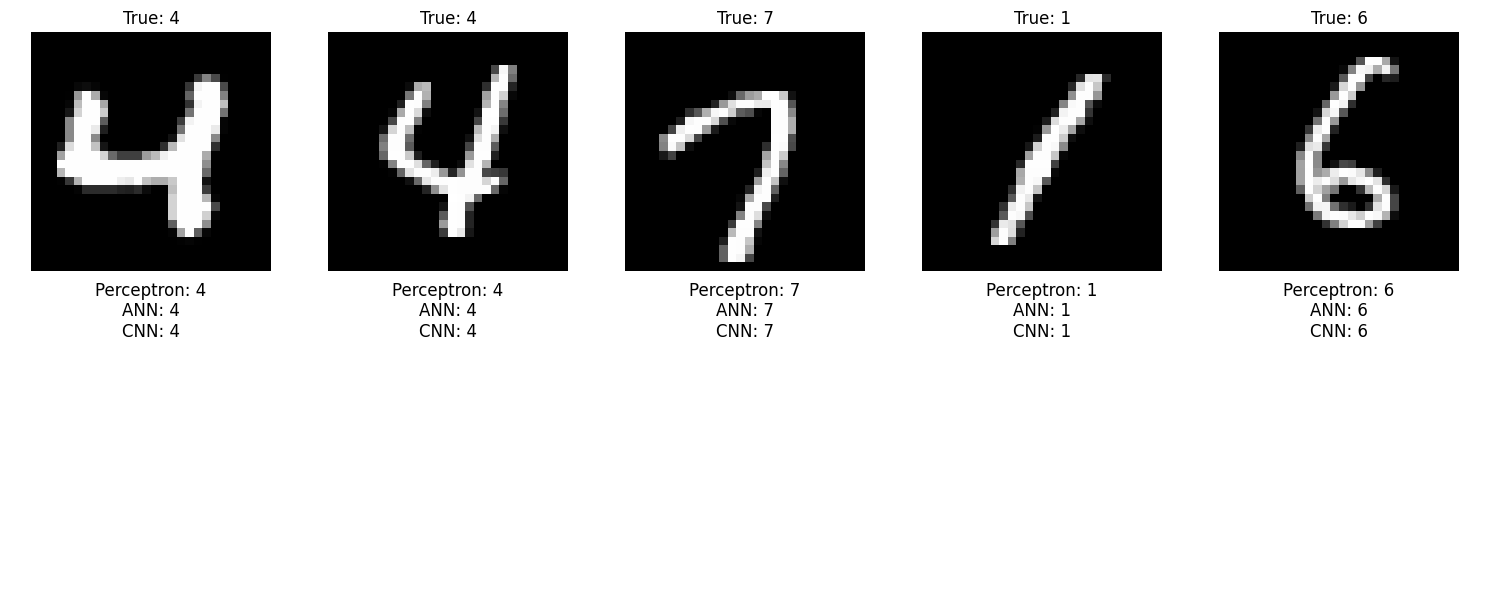

In [86]:
show_side_by_side([perceptron, ann, cnn], ['Perceptron', 'ANN', 'CNN'], X_test_img, X_test_cnn, y_test,5)

313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step


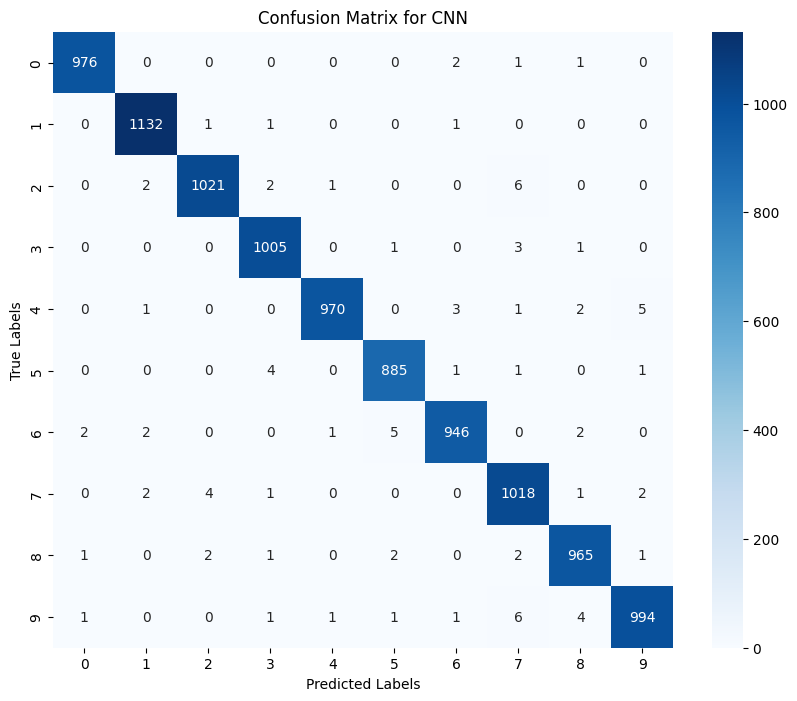

In [87]:
y_pred_cnn = np.argmax(cnn.predict(X_test_cnn), axis=1)
cm = confusion_matrix(y_test, y_pred_cnn)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(10), yticklabels=range(10))
plt.title('Confusion Matrix for CNN')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

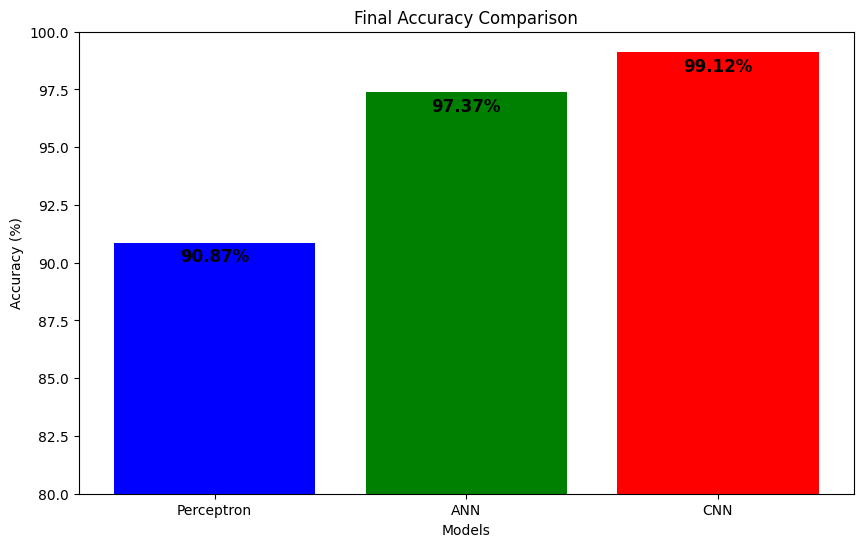

In [88]:
final_accs = [acc_percep*100, acc_ann*100, acc_cnn*100 ]
models = ['Perceptron', 'ANN', 'CNN']

plt.figure(figsize=(10, 6))
bar = plt.bar(models, final_accs, color=['blue', 'green', 'red'])
plt.title('Final Accuracy Comparison')
plt.xlabel('Models')
plt.ylabel('Accuracy (%)')
for bar, acc in zip(bar, final_accs):
  plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height()-1, f'{acc:.2f}%', ha='center', va='bottom', fontsize=12, fontweight = 'bold')
plt.ylim(80, 100)
plt.show()

